K nearest neighbors

Given a dataset of fruits, each is characterized by weight and sweetness level. Goal: To classify the new fruit as either "Apple" or "Orange" using KNN. 

- use k=3, new fruit = weight = 165, sweetness = 5.5, label?
- calc euclidean, manhattan, minkowski between new and existing
- effect of choosing different values of k
- without scikit library and plot with decision boundary

ID Label Euclidean Manhattan Minkowski (p=3)
1 Apple 15.075 16.5 15.005
2 Apple 35.004 35.5 35.0
3 Orange 15.075 16.5 15.005
4 Orange 5.025 5.5 5.002
5 Apple 5.025 5.5 5.002
6 Orange 25.125 27.5 25.008
euclidean
k = 1 -> Orange
k = 3 -> Apple
k = 5 -> Orange
manhattan
k = 1 -> Orange
k = 3 -> Apple
k = 5 -> Orange
minkowski
k = 1 -> Orange
k = 3 -> Apple
k = 5 -> Orange


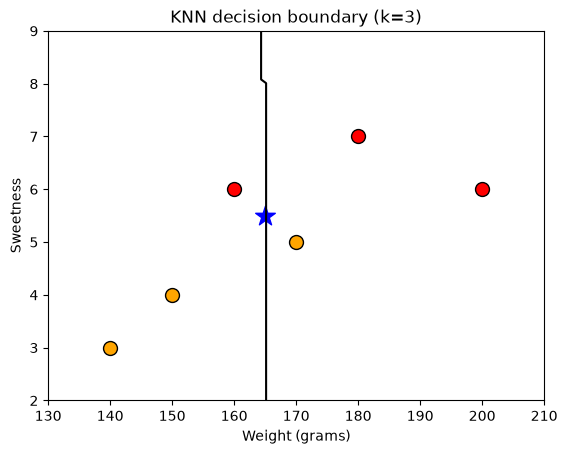

In [ ]:
import math
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

# Each row is [weight, sweetness]
X = np.array([[180, 7], [200, 6], [150, 4], [170, 5], [160, 6], [140, 3]])
y = np.array(["Apple", "Apple", "Orange", "Orange", "Apple", "Orange"])

new_fruit = np.array([165, 5.5])

def distance(a, b, metric):
    diff = np.abs(a - b)
    if metric == "euclidean":
        return math.sqrt(np.sum(diff ** 2))
    elif metric == "manhattan":
        return np.sum(diff)
    elif metric == "minkowski":
        p = 3
        return np.sum(diff ** p) ** (1 / p)


def knn(point, k, metric="euclidean"):
    distances = []

    for i in range(len(X)):
        d = distance(point, X[i], metric)
        distances.append((d, y[i]))

    distances.sort(key=lambda x: x[0])
    nearest_labels = []

    for d, label in distances[:k]:
        nearest_labels.append(label)

    return Counter(nearest_labels).most_common(1)[0][0]


# Compare all three distances
print("ID Label Euclidean Manhattan Minkowski (p=3)")

for i in range(len(X)):
    e = distance(new_fruit, X[i], "euclidean")
    m = distance(new_fruit, X[i], "manhattan")
    p = distance(new_fruit, X[i], "minkowski")

    print(i + 1, y[i], round(e, 3), round(m, 3), round(p, 3))


# Check how k affects the prediction
for metric in ["euclidean", "manhattan", "minkowski"]:
    print(metric)
    for k in [1, 3, 5]:
        print("k =", k, "->", knn(new_fruit, k))


# Decision boundary using Euclidean distance and k=3
weights = np.linspace(130, 210, 100)
sweetness = np.linspace(2, 9, 100)
xx, yy = np.meshgrid(weights, sweetness)

regions = np.zeros(xx.shape)

for row in range(100):
    for col in range(100):
        point = np.array([xx[row, col], yy[row, col]])

        if knn(point, 3) == "Orange":
            regions[row, col] = 1

plt.contour(xx, yy, regions,levels=[0.5],colors="black")

for i in range(len(X)):
    if y[i] == "Apple":
        color = "red"
    else:
        color = "orange"

    plt.scatter(X[i][0], X[i][1],color=color, edgecolor="black", s=100)

plt.scatter(new_fruit[0], new_fruit[1], color="blue", marker="*", s=220)

plt.xlabel("Weight (grams)")
plt.ylabel("Sweetness")
plt.title("KNN decision boundary (k=3)")
plt.show()